<a href="https://colab.research.google.com/github/HannaVar1/belhard_project/blob/main/03_capture_regression_B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

В эксперименте B к боевым характеристикам, росту и весу добавлены основные и вторичные типы, цвет и форма тела. Категории кодируются через One-Hot Encoding; отсутствие второго типа представлено отдельной категорией. Все преобразования обучаются только на train.

Используется сохранённое групповое разбиение эксперимента A. Архитектура и настройки MLP сохранены, а параметры SVR заново выбираются по той же сетке на validation. Основная метрика — MAE в исходных единицах capture_rate. Тестовая выборка не используется для настройки моделей.

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path
import copy
import random

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from IPython.display import display

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
)
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.svm import SVR
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

SEED = 42

NUMERIC_FEATURES = [
    "hp", "attack", "defense",
    "sp_attack", "sp_defense", "speed",
    "height_m", "weight_kg",
]

CATEGORICAL_FEATURES = [
    "type_1", "type_2", "color", "shape",
]

FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

TARGET = "capture_rate"
GROUP = "evolution_chain_id"

DATA_PATH = Path(
    "/content/drive/MyDrive/datasets/pokemon_complete.csv"
)

# Используем именно регрессионное разбиение A,
# а не разбиение классификации.
SPLIT_A_PATH = Path(
    "/content/drive/MyDrive/regression_results_A/split.csv"
)

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/regression_results_B"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MAX_EPOCHS = 300
PATIENCE = 25
BATCH_SIZE = 32
LEARNING_RATE = 0.001
DEVICE = torch.device("cpu")

RANGE_BINS = [-1, 30, 100, 200, 255]
RANGE_LABELS = ["0–30", "31–100", "101–200", "201–255"]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

sns.set_theme(style="whitegrid")


def save_plot(filename):
    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / filename,
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()


def regression_metrics(y_true, prediction):
    prediction = np.asarray(prediction).ravel()

    return {
        "MAE": mean_absolute_error(y_true, prediction),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, prediction)
        ),
        "R2": r2_score(y_true, prediction),
        "outside_0_255": int(
            ((prediction < 0) | (prediction > 255)).sum()
        ),
    }


if not DATA_PATH.is_file():
    raise FileNotFoundError(f"CSV не найден: {DATA_PATH}")

raw = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

required = [
    "pokedex_number", "name", GROUP, TARGET, *FEATURES
]

missing = set(required) - set(raw.columns)

if missing:
    raise ValueError(f"Отсутствуют столбцы: {sorted(missing)}")

raw["pokedex_number"] = pd.to_numeric(
    raw["pokedex_number"], errors="raise"
)

# Тот же отбор основных записей, что в A.
df = raw.loc[
    raw["pokedex_number"].between(1, 1025)
].copy().reset_index(drop=True)

if df.empty or not df["pokedex_number"].is_unique:
    raise ValueError("Пустая выборка или повторяющиеся ID")

numeric_columns = [GROUP, TARGET, *NUMERIC_FEATURES]

df[numeric_columns] = df[numeric_columns].apply(
    pd.to_numeric, errors="raise"
)

if df[numeric_columns].isna().any().any():
    raise ValueError(
        "Пропуски в числовых полях:\n"
        + df[numeric_columns].isna().sum().to_string()
    )

if not np.isfinite(
    df[numeric_columns].to_numpy(dtype=float)
).all():
    raise ValueError("Бесконечные числовые значения")

if (df[NUMERIC_FEATURES] < 0).any().any():
    raise ValueError("Отрицательные значения признаков")

if not df[TARGET].between(0, 255).all():
    raise ValueError("Capture rate вне диапазона 0–255")

# Отсутствие второго типа — отдельная допустимая категория.
df["type_2"] = (
    df["type_2"]
    .fillna("__none__")
    .astype(str)
    .str.strip()
    .replace("", "__none__")
)

for column in ["type_1", "color", "shape"]:
    if df[column].isna().any():
        raise ValueError(f"Пропуски в {column}")

    df[column] = df[column].astype(str).str.strip()

    if df[column].eq("").any():
        raise ValueError(f"Пустые категории в {column}")

print("Эксперимент B: числовые и категориальные признаки")
print("Объектов:", len(df))
print("Признаки:", FEATURES)

display(df[FEATURES + [TARGET]].head())

Эксперимент B: числовые и категориальные признаки
Объектов: 1025
Признаки: ['hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed', 'height_m', 'weight_kg', 'type_1', 'type_2', 'color', 'shape']


,hp,attack,defense,sp_attack,sp_defense,speed,height_m,weight_kg,type_1,type_2,color,shape,capture_rate
0,45,49,49,65,65,45,0.7,6.9,Grass,Poison,green,quadruped,45
1,60,62,63,80,80,60,1.0,13.0,Grass,Poison,green,quadruped,45
2,80,82,83,100,100,80,2.0,100.0,Grass,Poison,green,quadruped,45
3,39,52,43,60,50,65,0.6,8.5,Fire,__none__,red,upright,45
4,58,64,58,80,65,80,1.1,19.0,Fire,__none__,red,upright,45


In [ ]:
if not SPLIT_A_PATH.is_file():
    raise FileNotFoundError(
        f"Не найден регрессионный split A: {SPLIT_A_PATH}"
    )

saved_split = pd.read_csv(
    SPLIT_A_PATH, encoding="utf-8-sig"
)

required_split = [
    "pokedex_number", GROUP, TARGET, "split"
]

missing = set(required_split) - set(saved_split.columns)

if missing:
    raise ValueError(f"В split.csv отсутствуют поля: {sorted(missing)}")

if saved_split[required_split].isna().any().any():
    raise ValueError("Пропуски в split.csv")

for column in ["pokedex_number", GROUP, TARGET]:
    saved_split[column] = pd.to_numeric(
        saved_split[column], errors="raise"
    )

saved_split["split"] = (
    saved_split["split"].astype(str).str.strip()
)

if not saved_split["pokedex_number"].is_unique:
    raise ValueError("Повторяющиеся ID в split.csv")

if set(saved_split["split"]) != {
    "train", "validation", "test"
}:
    raise ValueError("Некорректные названия частей")

if set(saved_split["pokedex_number"]) != set(df["pokedex_number"]):
    raise ValueError("Набор объектов отличается от эксперимента A")

reference = saved_split.set_index("pokedex_number")
current = df.set_index("pokedex_number")

for column in [GROUP, TARGET]:
    old = reference[column].reindex(current.index)
    same = old.eq(current[column]).fillna(False)

    if not same.all():
        raise ValueError(
            f"Изменилось поле {column} у ID: "
            f"{current.index[~same].tolist()[:20]}"
        )

# Сохраняем порядок объектов из split A.
parts = {
    name: current.loc[
        saved_split.loc[
            saved_split["split"] == name,
            "pokedex_number",
        ].tolist()
    ].reset_index()
    for name in ["train", "validation", "test"]
}

train = parts["train"]
val = parts["validation"]
test = parts["test"]

expected_sizes = {
    "train": 662,
    "validation": 160,
    "test": 203,
}

for name, expected in expected_sizes.items():
    if len(parts[name]) != expected:
        raise ValueError(
            f"{name}: ожидалось {expected}, получено {len(parts[name])}. "
            "Проверьте, что загружен нужный split A."
        )

for first, second in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]:
    if set(parts[first][GROUP]) & set(parts[second][GROUP]):
        raise ValueError(f"Пересечение цепочек: {first}/{second}")

all_ids = pd.concat([
    part["pokedex_number"] for part in parts.values()
])

if (
    not all_ids.is_unique
    or len(all_ids) != len(df)
    or set(all_ids) != set(df["pokedex_number"])
):
    raise ValueError("Некорректное распределение объектов")

summary = pd.DataFrame([
    {
        "split": name,
        "rows": len(part),
        "chains": part[GROUP].nunique(),
        "target_mean": part[TARGET].mean(),
        "target_median": part[TARGET].median(),
    }
    for name, part in parts.items()
])

display(summary.round(2))

saved_split.to_csv(
    OUTPUT_DIR / "split.csv",
    index=False,
    encoding="utf-8-sig",
)

summary.to_csv(
    OUTPUT_DIR / "split_summary.csv",
    index=False,
)

# Проверяем категории validation, которых не было в train.
for column in CATEGORICAL_FEATURES:
    unknown = set(val[column]) - set(train[column])
    print(f"Новые категории {column} в validation:", sorted(unknown))

print(
    "Используется split A. "
    "Значения всех признаков должны соответствовать той же версии CSV: "
    "split.csv проверяет ID, target и цепочки, но не хранит снимок признаков."
)

,split,rows,chains,target_mean,target_median
0,train,662,345,95.89,60.0
1,validation,160,87,87.66,55.0
2,test,203,109,100.17,60.0


Новые категории type_1 в validation: []
Новые категории type_2 в validation: []
Новые категории color в validation: []
Новые категории shape в validation: []
Используется split A. Значения всех признаков должны соответствовать той же версии CSV: split.csv проверяет ID, target и цепочки, но не хранит снимок признаков.


In [ ]:
def create_preprocessor():
    return ColumnTransformer(
        transformers=[
            (
                "numeric",
                StandardScaler(),
                NUMERIC_FEATURES,
            ),
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                ),
                CATEGORICAL_FEATURES,
            ),
        ],
        sparse_threshold=0,
    )


# Baseline не использует значения признаков.
baseline_median = DummyRegressor(strategy="median")
baseline_mean = DummyRegressor(strategy="mean")

baseline_median.fit(
    np.zeros((len(train), 1)), train[TARGET]
)
baseline_mean.fit(
    np.zeros((len(train), 1)), train[TARGET]
)

print("Медиана train:", train[TARGET].median())
print("Среднее train:", train[TARGET].mean())

svr_models = {}
svr_rows = []

# Та же сетка, что и в A.
for C in [0.1, 1, 10, 100]:
    for gamma in ["scale", 0.01, 0.1]:
        for epsilon in [0.01, 0.1, 0.2]:
            candidate = TransformedTargetRegressor(
                regressor=make_pipeline(
                    create_preprocessor(),
                    SVR(
                        kernel="rbf",
                        C=C,
                        gamma=gamma,
                        epsilon=epsilon,
                    ),
                ),
                transformer=StandardScaler(),
            )

            candidate.fit(train[FEATURES], train[TARGET])

            # predict возвращает исходные единицы capture_rate.
            prediction = candidate.predict(val[FEATURES])

            key = (float(C), str(gamma), float(epsilon))
            svr_models[key] = candidate

            svr_rows.append({
                "C": C,
                "gamma": str(gamma),
                "epsilon_scaled_target": epsilon,
                **regression_metrics(val[TARGET], prediction),
            })

svr_search = pd.DataFrame(svr_rows).sort_values(
    "MAE",
    ascending=True,
    kind="stable",
)

display(svr_search.head(15).round(4))

best_row = svr_search.iloc[0]

svr = svr_models[(
    float(best_row["C"]),
    best_row["gamma"],
    float(best_row["epsilon_scaled_target"]),
)]

print("Выбранные параметры SVR B:")
display(best_row.to_frame("value"))

svr_search.to_csv(
    OUTPUT_DIR / "svr_validation_search.csv",
    index=False,
)

# C и epsilon относятся к стандартизованному target.
# Параметры выбираются по validation MAE, не по test.

Медиана train: 60.0
Среднее train: 95.89425981873111


,C,gamma,epsilon_scaled_target,MAE,RMSE,R2,outside_0_255
23,10.0,0.01,0.20,34.1114,47.7450,0.5429,3
21,10.0,0.01,0.01,34.3880,49.5142,0.5084,4
10,1.0,scale,0.10,34.4084,48.1220,0.5356,2
22,10.0,0.01,0.10,34.6420,49.2546,0.5135,4
9,1.0,scale,0.01,34.6430,48.9527,0.5195,3
15,1.0,0.1,0.01,34.7893,48.9541,0.5194,3
16,1.0,0.1,0.10,34.8287,48.5061,0.5282,2
11,1.0,scale,0.20,34.9307,48.0368,0.5373,0
12,1.0,0.01,0.01,35.0773,49.9893,0.4989,4
13,1.0,0.01,0.10,35.1420,49.5592,0.5075,5


Выбранные параметры SVR B:


,value
C,10.0
gamma,0.01
epsilon_scaled_target,0.2
MAE,34.111398
RMSE,47.74496
R2,0.542891
outside_0_255,3


Входных признаков после кодирования: 69
['numeric__hp' 'numeric__attack' 'numeric__defense' 'numeric__sp_attack'
 'numeric__sp_defense' 'numeric__speed' 'numeric__height_m'
 'numeric__weight_kg' 'categorical__type_1_Bug' 'categorical__type_1_Dark'
 'categorical__type_1_Dragon' 'categorical__type_1_Electric'
 'categorical__type_1_Fairy' 'categorical__type_1_Fighting'
 'categorical__type_1_Fire' 'categorical__type_1_Flying'
 'categorical__type_1_Ghost' 'categorical__type_1_Grass'
 'categorical__type_1_Ground' 'categorical__type_1_Ice'
 'categorical__type_1_Normal' 'categorical__type_1_Poison'
 'categorical__type_1_Psychic' 'categorical__type_1_Rock'
 'categorical__type_1_Steel' 'categorical__type_1_Water'
 'categorical__type_2_Bug' 'categorical__type_2_Dark'
 'categorical__type_2_Dragon' 'categorical__type_2_Electric'
 'categorical__type_2_Fairy' 'categorical__type_2_Fighting'
 'categorical__type_2_Fire' 'categorical__type_2_Flying'
 'categorical__type_2_Ghost' 'categorical__type_2_Grass

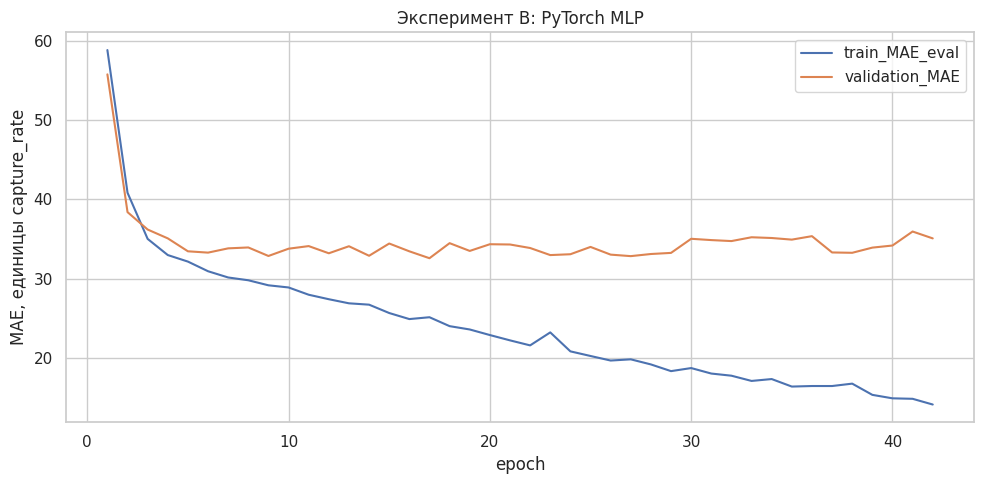

In [ ]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

feature_preprocessor = create_preprocessor()
target_scaler = StandardScaler()

X_train = feature_preprocessor.fit_transform(
    train[FEATURES]
).astype("float32")

X_val = feature_preprocessor.transform(
    val[FEATURES]
).astype("float32")

y_train_scaled = target_scaler.fit_transform(
    train[[TARGET]]
).astype("float32")

input_dim = X_train.shape[1]

print("Входных признаков после кодирования:", input_dim)
print(feature_preprocessor.get_feature_names_out())

train_dataset = TensorDataset(
    torch.from_numpy(X_train),
    torch.from_numpy(y_train_scaled),
)

generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator,
)

X_train_tensor = torch.from_numpy(X_train).to(DEVICE)
X_val_tensor = torch.from_numpy(X_val).to(DEVICE)

mlp = nn.Sequential(
    nn.Linear(input_dim, 64),
    nn.ReLU(),
    nn.Dropout(0.1),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1),
).to(DEVICE)

criterion = nn.L1Loss()

optimizer = torch.optim.Adam(
    mlp.parameters(),
    lr=LEARNING_RATE,
)

history_rows = []
best_val_mae = float("inf")
best_state = None
best_epoch = 0
waiting = 0

for epoch in range(1, MAX_EPOCHS + 1):
    mlp.train()
    total_loss = 0.0

    for xb, yb in train_loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        optimizer.zero_grad()
        prediction_scaled = mlp(xb)

        loss = criterion(prediction_scaled, yb)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(xb)

    mlp.eval()

    with torch.no_grad():
        train_prediction_scaled = (
            mlp(X_train_tensor).cpu().numpy()
        )
        val_prediction_scaled = (
            mlp(X_val_tensor).cpu().numpy()
        )

    train_prediction = target_scaler.inverse_transform(
        train_prediction_scaled
    ).ravel()

    val_prediction = target_scaler.inverse_transform(
        val_prediction_scaled
    ).ravel()

    train_mae = mean_absolute_error(
        train[TARGET], train_prediction
    )
    val_mae = mean_absolute_error(
        val[TARGET], val_prediction
    )

    history_rows.append({
        "epoch": epoch,
        "train_scaled_loss": total_loss / len(train_dataset),
        "train_MAE_eval": train_mae,
        "validation_MAE": val_mae,
    })

    if val_mae < best_val_mae:
        best_val_mae = val_mae
        best_state = copy.deepcopy(mlp.state_dict())
        best_epoch = epoch
        waiting = 0
    else:
        waiting += 1

    if epoch == 1 or epoch % 20 == 0:
        print(
            f"Epoch {epoch:3d} | "
            f"train MAE={train_mae:.2f} | "
            f"validation MAE={val_mae:.2f}"
        )

    if waiting >= PATIENCE:
        print(f"Ранняя остановка на эпохе {epoch}")
        break

mlp.load_state_dict(best_state)
mlp.eval()

print(
    f"Лучшая эпоха: {best_epoch}; "
    f"validation MAE: {best_val_mae:.2f}"
)

history = pd.DataFrame(history_rows)
history.to_csv(OUTPUT_DIR / "mlp_history.csv", index=False)

history.plot(
    x="epoch",
    y=["train_MAE_eval", "validation_MAE"],
    figsize=(10, 5),
)
plt.title("Эксперимент B: PyTorch MLP")
plt.ylabel("MAE, единицы capture_rate")
save_plot("mlp_mae.png")

In [ ]:
def predict_mlp(part):
    X = feature_preprocessor.transform(
        part[FEATURES]
    ).astype("float32")

    mlp.eval()

    with torch.no_grad():
        scaled_prediction = (
            mlp(torch.from_numpy(X).to(DEVICE))
            .cpu()
            .numpy()
        )

    return target_scaler.inverse_transform(
        scaled_prediction
    ).ravel()


def predict_models(part):
    return {
        "Dummy median": baseline_median.predict(
            np.zeros((len(part), 1))
        ),
        "Dummy mean": baseline_mean.predict(
            np.zeros((len(part), 1))
        ),
        "SVR RBF": svr.predict(part[FEATURES]),
        "PyTorch MLP": predict_mlp(part),
    }


metric_rows = []
validation_predictions = None

for split_name, part in {
    "train": train,
    "validation": val,
}.items():
    predictions = predict_models(part)

    if split_name == "validation":
        validation_predictions = predictions

    for model_name, prediction in predictions.items():
        metric_rows.append({
            "split": split_name,
            "model": model_name,
            **regression_metrics(part[TARGET], prediction),
        })

metrics_B = pd.DataFrame(metric_rows)

print("Метрики B:")
display(metrics_B.round(3))

metrics_B.to_csv(
    OUTPUT_DIR / "train_validation_metrics.csv",
    index=False,
)

# Фактические validation-результаты A из вашего отчёта.
metrics_A = pd.DataFrame([
    {
        "model": "Dummy median",
        "MAE_A": 52.61875,
        "RMSE_A": 75.84074597470676,
        "R2_A": -0.15337392077220913,
    },
    {
        "model": "Dummy mean",
        "MAE_A": 60.32909743202417,
        "RMSE_A": 71.09722492271418,
        "R2_A": -0.01360847768672091,
    },
    {
        "model": "SVR RBF",
        "MAE_A": 35.64661725527476,
        "RMSE_A": 51.300818260199485,
        "R2_A": 0.4722678902038352,
    },
    {
        "model": "PyTorch MLP",
        "MAE_A": 34.69569778442383,
        "RMSE_A": 50.72518539733246,
        "R2_A": 0.48404449224472046,
    },
])

validation_B = metrics_B.loc[
    metrics_B["split"] == "validation",
    ["model", "MAE", "RMSE", "R2"],
].rename(columns={
    "MAE": "MAE_B",
    "RMSE": "RMSE_B",
    "R2": "R2_B",
})

comparison = metrics_A.merge(validation_B, on="model")

comparison["MAE_change_B_minus_A"] = (
    comparison["MAE_B"] - comparison["MAE_A"]
)
comparison["RMSE_change_B_minus_A"] = (
    comparison["RMSE_B"] - comparison["RMSE_A"]
)
comparison["R2_change_B_minus_A"] = (
    comparison["R2_B"] - comparison["R2_A"]
)

print("Сравнение A и B:")
display(comparison.round(3))

comparison.to_csv(
    OUTPUT_DIR / "comparison_A_B.csv",
    index=False,
)

print(
    "Отрицательное изменение MAE/RMSE — улучшение; "
    "положительное изменение R² — улучшение."
)

# Baseline должен повторить A: target и split не менялись.
for name in ["Dummy median", "Dummy mean"]:
    row = comparison.loc[comparison["model"] == name].iloc[0]

    if not np.isclose(row["MAE_A"], row["MAE_B"], atol=1e-6):
        print(
            f"Внимание: baseline {name} отличается от A. "
            "Проверьте данные и разбиение."
        )

trained_candidates = validation_B.loc[
    validation_B["model"].isin(["SVR RBF", "PyTorch MLP"])
]

recommended_model = trained_candidates.sort_values(
    "MAE_B", kind="stable"
).iloc[0]["model"]

print("Лучший обучаемый кандидат внутри B:", recommended_model)

# Это ещё не выбор победителя между всеми экспериментами A/B.

Метрики B:


,split,model,MAE,RMSE,R2,outside_0_255
0,train,Dummy median,58.565,84.173,-0.222,0
1,train,Dummy mean,64.071,76.136,0.000,0
2,train,SVR RBF,29.558,44.449,0.659,10
3,train,PyTorch MLP,25.127,41.326,0.705,3
4,validation,Dummy median,52.619,75.841,-0.153,0
5,validation,Dummy mean,60.329,71.097,-0.014,0
6,validation,SVR RBF,34.111,47.745,0.543,3
7,validation,PyTorch MLP,32.571,47.804,0.542,3


Сравнение A и B:


,model,MAE_A,RMSE_A,R2_A,MAE_B,RMSE_B,R2_B,MAE_change_B_minus_A,RMSE_change_B_minus_A,R2_change_B_minus_A
0,Dummy median,52.619,75.841,-0.153,52.619,75.841,-0.153,0.000,0.000,0.000
1,Dummy mean,60.329,71.097,-0.014,60.329,71.097,-0.014,0.000,0.000,0.000
2,SVR RBF,35.647,51.301,0.472,34.111,47.745,0.543,-1.535,-3.556,0.071
3,PyTorch MLP,34.696,50.725,0.484,32.571,47.804,0.542,-2.125,-2.921,0.058


Отрицательное изменение MAE/RMSE — улучшение; положительное изменение R² — улучшение.
Лучший обучаемый кандидат внутри B: PyTorch MLP



Dummy median
Ошибки по диапазонам:


,count,MAE,mean_residual,model
target_range,,,,
0–30,24,48.62,-48.62,Dummy median
31–100,90,16.11,-2.33,Dummy median
101–200,34,104.18,104.18,Dummy median
201–255,12,188.33,188.33,Dummy median


Наибольшие ошибки:


,pokedex_number,name,evolution_chain_id,capture_rate,hp,attack,defense,sp_attack,sp_defense,speed,height_m,weight_kg,type_1,type_2,color,shape,prediction,residual,absolute_error,target_range
3,41,Zubat,17,255,40,45,35,30,40,55,0.8,7.5,Poison,Flying,purple,wings,60.0,195.0,195.0,201–255
10,69,Bellsprout,29,255,50,75,35,70,30,40,0.7,4.0,Grass,Poison,green,humanoid,60.0,195.0,195.0,201–255
30,161,Sentret,82,255,35,46,34,35,45,20,0.8,6.0,Normal,__none__,brown,quadruped,60.0,195.0,195.0,201–255
126,859,Impidimp,451,255,45,45,30,55,40,50,0.4,5.5,Dark,Fairy,pink,humanoid,60.0,195.0,195.0,201–255
68,396,Starly,206,255,40,55,30,30,30,60,0.3,2.0,Normal,Flying,brown,wings,60.0,195.0,195.0,201–255
74,436,Bronzor,224,255,57,24,86,24,86,23,0.5,60.5,Steel,Psychic,green,ball,60.0,195.0,195.0,201–255
51,285,Shroomish,142,255,60,40,60,40,60,35,0.4,4.5,Grass,__none__,brown,legs,60.0,195.0,195.0,201–255
56,328,Trapinch,166,255,45,100,45,45,45,10,0.7,15.0,Ground,__none__,brown,armor,60.0,195.0,195.0,201–255
122,831,Wooloo,438,255,42,40,55,40,45,48,0.6,6.0,Normal,__none__,white,quadruped,60.0,195.0,195.0,201–255
109,761,Bounsweet,392,235,42,30,38,30,38,32,0.3,3.2,Grass,__none__,purple,legs,60.0,175.0,175.0,201–255



Dummy mean
Ошибки по диапазонам:


,count,MAE,mean_residual,model
target_range,,,,
0–30,24,84.52,-84.52,Dummy mean
31–100,90,38.59,-38.23,Dummy mean
101–200,34,68.28,68.28,Dummy mean
201–255,12,152.44,152.44,Dummy mean


... (8 outputs left out)

Наибольшие ошибки:


,pokedex_number,name,evolution_chain_id,capture_rate,hp,attack,defense,sp_attack,sp_defense,speed,height_m,weight_kg,type_1,type_2,color,shape,prediction,residual,absolute_error,target_range
106,746,Wishiwashi-Solo,384,60,45,20,20,25,25,40,0.2,0.3,Water,__none__,blue,fish,276.673401,-216.673401,216.673401,31–100
74,436,Bronzor,224,255,57,24,86,24,86,23,0.5,60.5,Steel,Psychic,green,ball,105.214600,149.785400,149.785400,201–255
151,967,Cyclizar,506,190,70,95,65,85,65,121,1.6,63.0,Dragon,Normal,green,quadruped,44.024940,145.975060,145.975060,101–200
93,587,Emolga,298,200,55,75,60,75,60,103,0.4,5.0,Electric,Flying,white,quadruped,59.639725,140.360275,140.360275,101–200
95,633,Deino,323,45,52,65,50,45,50,38,0.8,17.3,Dark,Dragon,blue,quadruped,175.891342,-130.891342,130.891342,31–100
65,393,Piplup,205,45,53,51,53,61,56,40,0.4,5.2,Water,__none__,blue,humanoid,173.488876,-128.488876,128.488876,31–100
27,158,Totodile,81,45,50,65,64,44,48,43,0.6,9.5,Water,__none__,blue,upright,167.792892,-122.792892,122.792892,31–100
77,447,Riolu,232,75,40,70,40,35,40,60,0.7,20.2,Fighting,__none__,blue,upright,194.610352,-119.610352,119.610352,31–100
46,225,Delibird,115,45,45,55,45,65,45,75,0.9,16.0,Ice,Flying,red,wings,160.694016,-115.694016,115.694016,31–100
10,69,Bellsprout,29,255,50,75,35,70,30,40,0.7,4.0,Grass,Poison,green,humanoid,147.755722,107.244278,107.244278,201–255


Сводка ошибок:


,model,MAE,median_absolute_error,p90_absolute_error,mean_residual
0,Dummy median,52.62,30.00,131.00,27.66
1,Dummy mean,60.33,50.89,95.11,-8.24
2,SVR RBF,34.11,23.07,77.62,-6.90
3,PyTorch MLP,32.57,23.93,78.90,-2.86


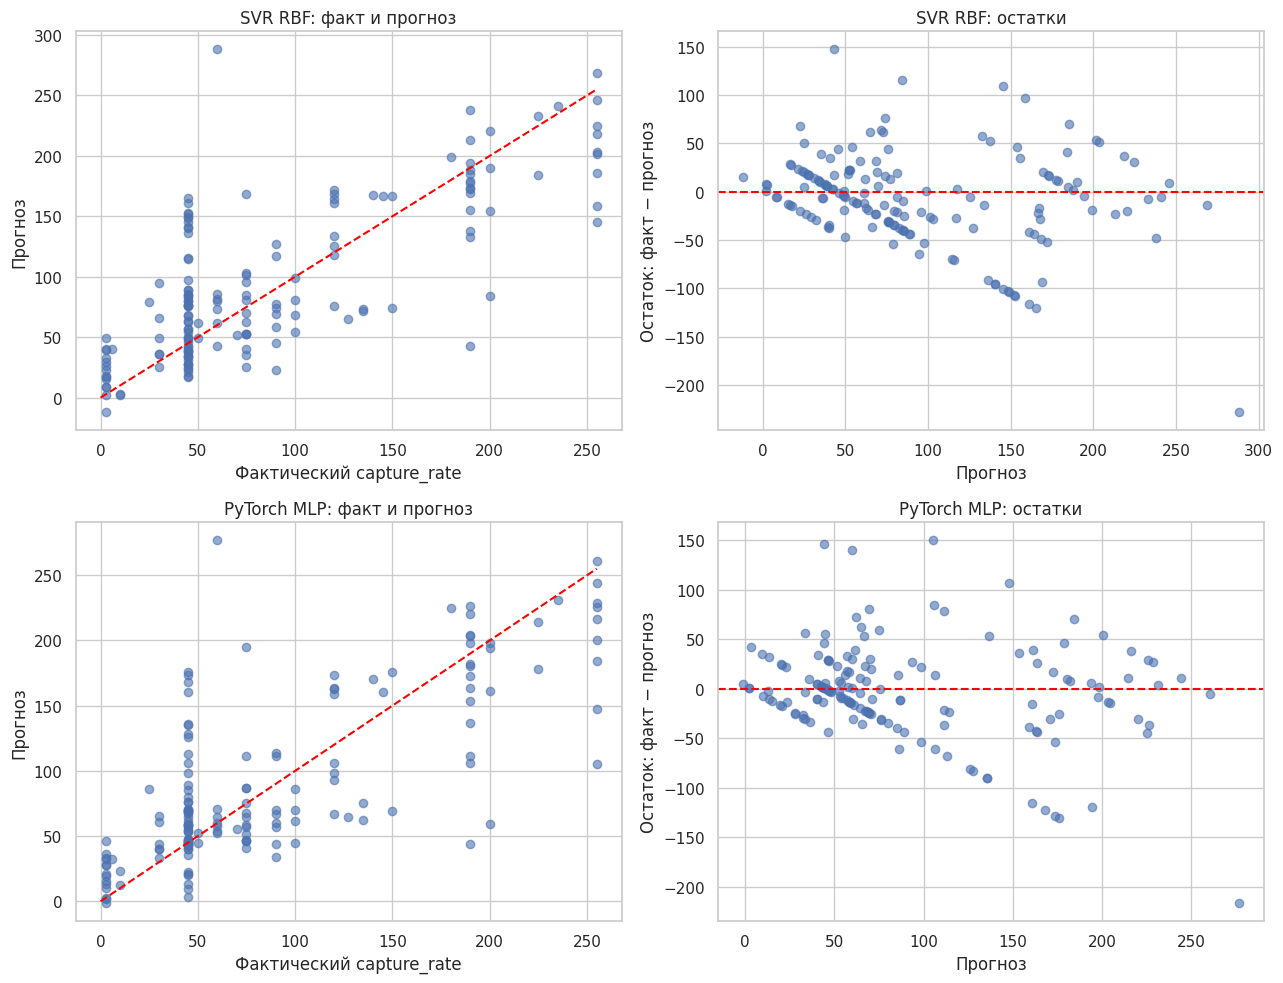

In [ ]:
error_summaries = []
range_tables = []

for model_name, prediction in validation_predictions.items():
    safe_name = model_name.lower().replace(" ", "_")

    analysis = val[
        ["pokedex_number", "name", GROUP, TARGET, *FEATURES]
    ].copy()

    analysis["prediction"] = prediction
    analysis["residual"] = (
        analysis[TARGET] - analysis["prediction"]
    )
    analysis["absolute_error"] = analysis["residual"].abs()

    analysis["target_range"] = pd.cut(
        analysis[TARGET],
        bins=RANGE_BINS,
        labels=RANGE_LABELS,
    )

    error_summaries.append({
        "model": model_name,
        "MAE": analysis["absolute_error"].mean(),
        "median_absolute_error": analysis["absolute_error"].median(),
        "p90_absolute_error": analysis["absolute_error"].quantile(0.9),
        "mean_residual": analysis["residual"].mean(),
    })

    range_summary = (
        analysis.groupby("target_range", observed=True)
        .agg(
            count=("absolute_error", "size"),
            MAE=("absolute_error", "mean"),
            mean_residual=("residual", "mean"),
        )
        .reindex(RANGE_LABELS)
    )

    range_summary["count"] = (
        range_summary["count"].fillna(0).astype(int)
    )
    # В пустых диапазонах MAE остаётся NaN.
    range_summary["model"] = model_name
    range_tables.append(range_summary.reset_index())

    print("\n" + "=" * 60)
    print(model_name)

    print("Ошибки по диапазонам:")
    display(range_summary.round(2))

    print("Наибольшие ошибки:")
    display(
        analysis.sort_values(
            "absolute_error", ascending=False
        ).head(15)
    )

    analysis.to_csv(
        OUTPUT_DIR / f"validation_{safe_name}_predictions.csv",
        index=False,
        encoding="utf-8-sig",
    )

error_summary = pd.DataFrame(error_summaries)
range_summary_all = pd.concat(range_tables, ignore_index=True)

print("Сводка ошибок:")
display(error_summary.round(2))

error_summary.to_csv(
    OUTPUT_DIR / "validation_error_summary.csv",
    index=False,
)

range_summary_all.to_csv(
    OUTPUT_DIR / "validation_errors_by_range.csv",
    index=False,
    encoding="utf-8-sig",
)

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for row, model_name in enumerate(["SVR RBF", "PyTorch MLP"]):
    prediction = validation_predictions[model_name]
    residual = val[TARGET].to_numpy() - prediction

    axes[row, 0].scatter(
        val[TARGET], prediction, alpha=0.6
    )
    axes[row, 0].plot(
        [0, 255], [0, 255], "--", color="red"
    )
    axes[row, 0].set_xlabel("Фактический capture_rate")
    axes[row, 0].set_ylabel("Прогноз")
    axes[row, 0].set_title(f"{model_name}: факт и прогноз")

    axes[row, 1].scatter(
        prediction, residual, alpha=0.6
    )
    axes[row, 1].axhline(
        0, color="red", linestyle="--"
    )
    axes[row, 1].set_xlabel("Прогноз")
    axes[row, 1].set_ylabel("Остаток: факт − прогноз")
    axes[row, 1].set_title(f"{model_name}: остатки")

save_plot("validation_predictions_and_residuals.png")

In [ ]:
clipping_rows = []

for model_name in ["SVR RBF", "PyTorch MLP"]:
    raw_prediction = validation_predictions[model_name]
    clipped_prediction = np.clip(raw_prediction, 0, 255)

    for variant, prediction in [
        ("raw", raw_prediction),
        ("clipped_0_255", clipped_prediction),
    ]:
        clipping_rows.append({
            "model": model_name,
            "prediction_variant": variant,
            **regression_metrics(val[TARGET], prediction),
        })

clipping_results = pd.DataFrame(clipping_rows)

print("Отдельная проверка ограничения диапазона:")
display(clipping_results.round(3))

clipping_results.to_csv(
    OUTPUT_DIR / "validation_clipping_comparison.csv",
    index=False,
)

# Для target в [0,255] clipping не увеличивает MAE/RMSE.
# Он не устраняет крупные ошибки внутри диапазона.
# Если выбираем clipping для итоговой оценки,
# фиксируем его до просмотра test и применяем одинаково к моделям.

Отдельная проверка ограничения диапазона:


,model,prediction_variant,MAE,RMSE,R2,outside_0_255
0,SVR RBF,raw,34.111,47.745,0.543,3
1,SVR RBF,clipped_0_255,33.744,46.794,0.561,0
2,PyTorch MLP,raw,32.571,47.804,0.542,3
3,PyTorch MLP,clipped_0_255,32.391,47.215,0.553,0


In [ ]:
joblib.dump(
    {
        "baseline_median": baseline_median,
        "baseline_mean": baseline_mean,
        "svr": svr,
        "mlp_feature_preprocessor": feature_preprocessor,
        "mlp_target_scaler": target_scaler,
        "numeric_features": NUMERIC_FEATURES,
        "categorical_features": CATEGORICAL_FEATURES,
        "features": FEATURES,
        "target": TARGET,
        "recommended_model": recommended_model,
        "prediction_postprocessing": "none",
        "seed": SEED,
    },
    OUTPUT_DIR / "regression_models.joblib",
)

torch.save(
    {
        "state_dict": mlp.state_dict(),
        "input_dim": input_dim,
        "features": FEATURES,
        "target": TARGET,
        "best_epoch": best_epoch,
        "seed": SEED,
        "dropout": 0.1,
    },
    OUTPUT_DIR / "mlp_checkpoint.pt",
)

print("Результаты сохранены:", OUTPUT_DIR)
print("Test не оценивался.")

# Загружайте joblib и checkpoint только из доверенных источников.

Результаты сохранены: /content/drive/MyDrive/regression_results_B
Test не оценивался.


Добавление основных и вторичных типов, цвета и формы тела улучшило качество регрессии обеих моделей на фиксированной проверочной выборке. MAE SVR снизилась с 35,65 до 34,11, а PyTorch MLP — с 34,70 до 32,57. По RMSE и R² модели показали практически одинаковые результаты.

Преимущество MLP по MAE связано преимущественно с улучшением прогнозов в наиболее многочисленном диапазоне 31–100. Обе модели также снизили ошибки на высоких значениях 201–255, однако систематическое завышение низких и занижение высоких значений сохранилось.

Кривая обучения MLP демонстрирует переобучение: обучающая ошибка продолжает уменьшаться без устойчивого улучшения validation. Для итоговой оценки используется checkpoint с минимальной validation MAE. MLP B выбрана предварительным кандидатом по основной метрике; результат необходимо проверить на независимом test.